# PlantNet-300K baseline: results summary

The Phase 1 species classifier (Roadmap) trained on PlantNet-300K: the
dataset's class imbalance, the trained baseline's scores (and how they
split by how much training data a species had), a qualitative look at
specific cat-toxicity-relevant species, and a baseline breakdown by
toxicity-table relevance to compare future toxicity-aware training
against.

Self-contained - reproducible by re-running top to bottom against
`outputs/plantnet-baseline/` and `data/raw/plantnet/`.

In [12]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from plant_toxicity_checker.config import (
    PLANTNET_DIR,
    REPO_ROOT,
    TOXICITY_TABLE_PATH,
)
from plant_toxicity_checker.plantnet_dataset import (
    images_per_species,
    load_metadata,
    rows_for_split,
)
from plant_toxicity_checker.plantnet_labels import load_species_rows
from plant_toxicity_checker.species_match import (
    match_against_toxicity_table,
    toxicity_category,
)
from plant_toxicity_checker.toxicity import load_table

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

RUN_NAME = "plantnet-baseline"
OUT_DIR = REPO_ROOT / "outputs" / RUN_NAME
IMAGES_DIR = PLANTNET_DIR / "images"

# The one place this project decides how PlantNet species relate to
# the toxicity table (species_match.match_against_toxicity_table) -
# genus+epithet matching against data/toxicity.json, never the raw
# ASPCA scrape directly and never common names. Every entry in that
# table is still "verified": false (see toxicity_seed.py) - this is
# illustrative grouping, never a real safety verdict.
species_rows = load_species_rows()
toxicity_table = load_table(TOXICITY_TABLE_PATH)
toxicity_matches = match_against_toxicity_table(species_rows, toxicity_table)

CAT_TOXIC_SPECIES_IDS = sorted(
    species_id for species_id, result in toxicity_matches.items()
    if result.status == "exact" and result.exact_row.toxic_to_cats == "yes"
)
print(f"{len(CAT_TOXIC_SPECIES_IDS)} PlantNet species exactly match a "
      f"cat-toxic entry in the toxicity table: {CAT_TOXIC_SPECIES_IDS}")

ImportError: cannot import name 'TOXICITY_TABLE_PATH' from 'plant_toxicity_checker.config' (C:\Users\carl0\vsc\cat-project\plant_toxicity_checker\config.py)

## 1 · The dataset

`plantnet300K_metadata.csv` is per-image (one row per photo); the
`species` column groups them into PlantNet-300K's 1000 species.

In [ ]:
all_rows = load_metadata()
train_rows = rows_for_split(all_rows, "train")
val_rows = rows_for_split(all_rows, "val")
test_rows = rows_for_split(all_rows, "test")
train_counts = images_per_species(train_rows)

print(f"train: {len(train_rows):,} images   val: {len(val_rows):,} images   test: {len(test_rows):,} images")
print(f"species: {len(train_counts)}")

counts = pd.Series(train_counts).sort_values(ascending=False)
summary = pd.DataFrame({
    "images/species (train)": [
        counts.min(), counts.quantile(0.5), round(counts.mean(), 1),
        counts.max(), (counts < 20).sum(), (counts < 20).sum() / len(counts),
    ],
}, index=["min", "median", "mean", "max", "species with <20 images",
          "share of species with <20 images"])
summary

train: 243,866 images   val: 31,115 images   test: 31,106 images
species: 1000


,images/species (train)
min,2.000
median,21.500
mean,243.900
max,7207.000
species with <20 images,477.000
share of species with <20 images,0.477


**Severely long-tailed.** A handful of very common species pull the
mean (244) far above the median (21) - almost half the species have
under 20 training images at all.

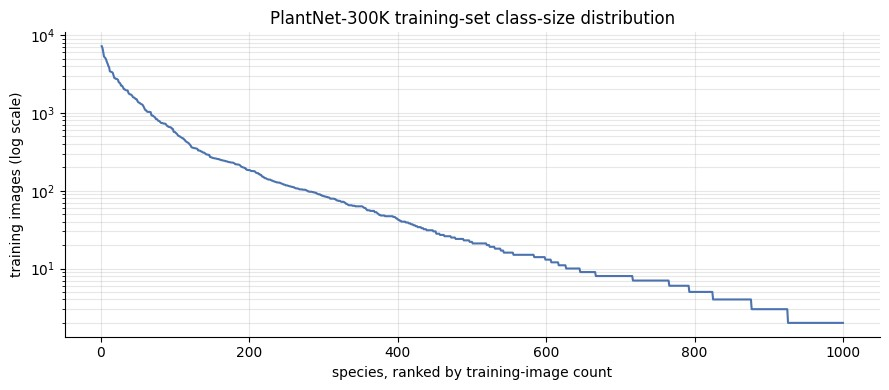

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ranks = np.arange(1, len(counts) + 1)
ax.plot(ranks, counts.values, color="#4c72b0")
ax.set_yscale("log")
ax.set_xlabel("species, ranked by training-image count")
ax.set_ylabel("training images (log scale)")
ax.set_title("PlantNet-300K training-set class-size distribution")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**A couple of examples** - what "common" vs "rare" actually looks
like: `Hypericum perforatum` had 6,140 training images; `Zamia pumila`
had 17.

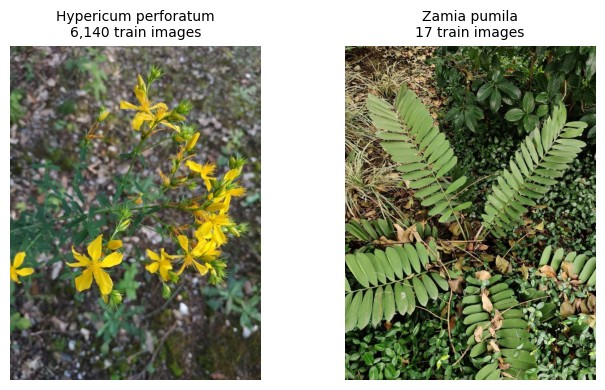

In [ ]:
def load_example_image(image_path):
    return Image.open(IMAGES_DIR / image_path)

examples = [
    ("val/0011/000ccbc3d460fe584a715f0f52647450b83e5823.jpg",
     "Hypericum perforatum\n6,140 train images"),
    ("val/0700/2585cde6aa23a1c5fc659c86584607747402b0be.jpg",
     "Zamia pumila\n17 train images"),
]

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
for ax, (path, caption) in zip(axes, examples):
    ax.imshow(load_example_image(path))
    ax.set_title(caption, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2 · Benchmark scores

The finished 30-epoch run (`configs/plantnet_baseline.json`: ResNet-18,
ImageNet-pretrained, SGD, LR decay ×0.1 at epochs 20 and 25).

In [ ]:
metrics = json.loads((OUT_DIR / "metrics.json").read_text(encoding="utf-8"))
config = json.loads((OUT_DIR / "config.json").read_text(encoding="utf-8"))

print(f"{metrics['epochs_run']} epochs")
print(f"val top-1: {metrics['val_top1']:.1%}")
print(f"val top-5: {metrics['val_top5']:.1%}")

30 epochs
val top-1: 81.2%
val top-5: 95.6%


**But that's one flat number across all 1,000 species.** Splitting
accuracy by how many training images each species had tells a very
different story - the overall numbers above are dominated by the
well-represented species.

In [ ]:
breakdown = json.loads(
    (OUT_DIR / "species_breakdown_val.json").read_text(encoding="utf-8")
)
buckets = breakdown["buckets"]
bucket_order = ["<20", "20-49", "50-199", "200+"]

bucket_df = pd.DataFrame({
    name: {
        "species": buckets[name]["n_species"],
        "val images": buckets[name]["n"],
        "top-1": buckets[name]["top1_accuracy"],
        "top-5": buckets[name]["top5_accuracy"],
    }
    for name in bucket_order
}).T
bucket_df

,species,val images,top-1,top-5
<20,477.0,710.0,0.130986,0.473239
20-49,149.0,671.0,0.374069,0.791356
50-199,183.0,2501.0,0.596561,0.906038
200+,191.0,27233.0,0.860684,0.977087


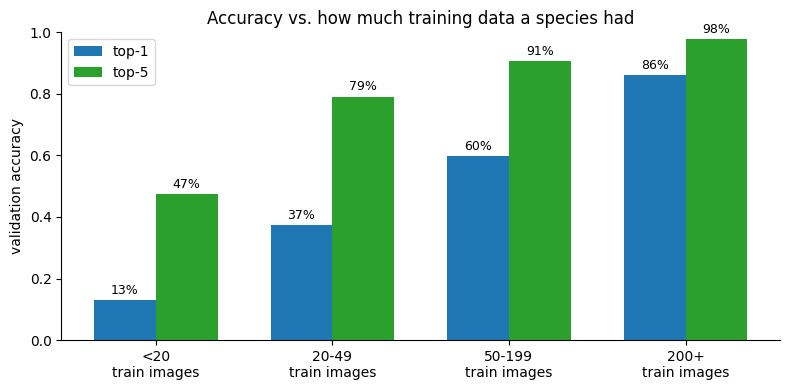

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(bucket_order))
width = 0.35
ax.bar(x - width / 2, bucket_df["top-1"], width, label="top-1", color="#1f77b4")
ax.bar(x + width / 2, bucket_df["top-5"], width, label="top-5", color="#2ca02c")
ax.set_xticks(x)
ax.set_xticklabels([f"{b}\ntrain images" for b in bucket_order])
ax.set_ylabel("validation accuracy")
ax.set_ylim(0, 1)
ax.set_title("Accuracy vs. how much training data a species had")
ax.legend()
for i, b in enumerate(bucket_order):
    ax.text(i - width / 2, bucket_df["top-1"][b] + 0.02, f"{bucket_df['top-1'][b]:.0%}", ha="center", fontsize=9)
    ax.text(i + width / 2, bucket_df["top-5"][b] + 0.02, f"{bucket_df['top-5'][b]:.0%}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 3 · Does it actually identify toxic species?

**Important caveat:** `data/toxicity.json` exists, but every entry in
it is still `"verified": false` (seeded from the ASPCA scrape by
`toxicity_seed.py`, not yet hand-checked) - so the "toxic" label below
is illustrative, never a real safety verdict. The model itself only
ever predicts a species, never "toxic"/"non-toxic" directly - that
separation is non-negotiable project-wide, regardless of the table's
verification status.

Of PlantNet-300K's 1,000 species, exactly 6 have an **exact** match in
the toxicity table with `toxic_to_cats: "yes"`. Three examples below,
spanning the full range of what we just saw: a clean hit, a near miss
(true species still in the top-5), and a complete miss.

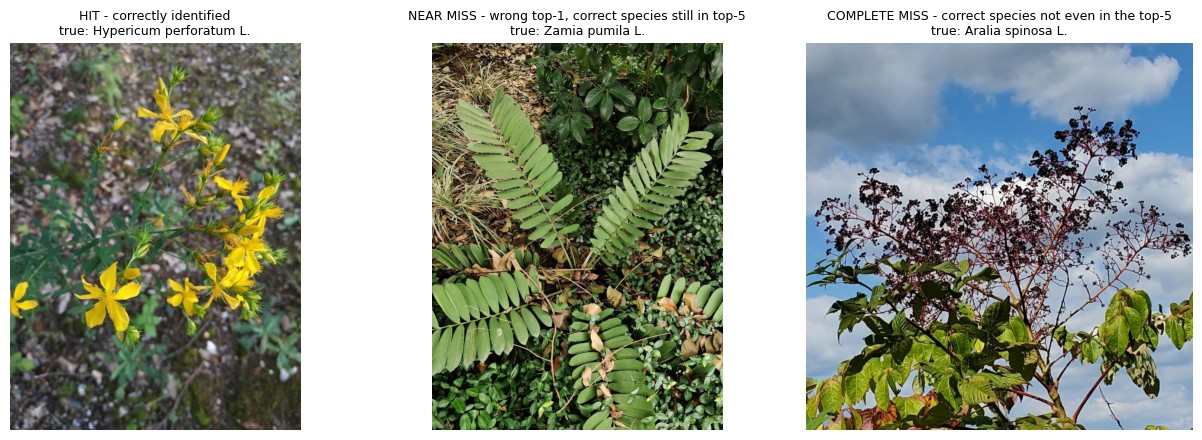

--- HIT - correctly identified ---
true species: Hypericum perforatum L.
  98.8%  Hypericum perforatum L. <-- true species
  0.6%  Hypericum perfoliatum L.
  0.3%  Hypericum linariifolium Vahl
  0.1%  Hypericum annulatum Moris
  0.1%  Hypericum hirsutum L.

--- NEAR MISS - wrong top-1, correct species still in top-5 ---
true species: Zamia pumila L.
  80.4%  Zamia furfuracea L.f. ex Aiton
  16.6%  Zamia pumila L. <-- true species
  2.3%  Osmunda regalis L.
  0.6%  Nephrolepis cordifolia (L.) C.Presl
  0.0%  Nephrolepis biserrata (Sw.) Schott

--- COMPLETE MISS - correct species not even in the top-5 ---
true species: Aralia spinosa L.
  16.1%  Aralia elata (Miq.) Seem.
  8.8%  Nothofagus antarctica (G.Forst.) Oerst.
  8.4%  Guaiacum officinale L.
  7.2%  Nothofagus dombeyi (Mirb.) Oerst.
  5.1%  Nothofagus nitida (Phil.) Krasser



In [ ]:
predictions = json.loads(
    (OUT_DIR / "toxic_examples_val.json").read_text(encoding="utf-8")
)
by_species = {}
for p in predictions:
    by_species.setdefault(p["species_id"], []).append(p)


def find(species_id, top1_correct, top5_correct):
    for p in by_species[species_id]:
        if p["top1_correct"] == top1_correct and p["top5_correct"] == top5_correct:
            return p
    return None


cases = [
    ("HIT - correctly identified", find(11, True, True)),
    ("NEAR MISS - wrong top-1, correct species still in top-5", find(700, False, True)),
    ("COMPLETE MISS - correct species not even in the top-5", find(861, False, False)),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (label, case) in zip(axes, cases):
    ax.imshow(Image.open(IMAGES_DIR / case["image_path"]))
    ax.set_title(f"{label}\ntrue: {case['true_name']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

for label, case in cases:
    print(f"--- {label} ---")
    print(f"true species: {case['true_name']}")
    for t in case["top5"]:
        marker = " <-- true species" if t["name"] == case["true_name"] else ""
        print(f"  {t['proba']:.1%}  {t['name']}{marker}")
    print()

## 4 · Baseline accuracy by toxicity-table relevance

The preparatory baseline for a future toxicity-aware training comparison
(Phase 2/3): for every one of the 1,000 PlantNet species, how it relates
to the toxicity table (`species_match.match_against_toxicity_table`) - an
**exact** match (the table has that exact species), a **genus**-level
match (the table has a relative in the same genus, not that exact
species), or no match at all - crossed with what the table says about
cats specifically for that match. These are the numbers a
toxicity-aware training objective would be trying to move.

Same caveat as section 3: every entry is still unverified, used for
illustrative grouping only - a "genus - non-toxic" label means "this
species' relatives in the table aren't cat-toxic", never "this species
itself is verified safe".

In [ ]:
cat_category = {
    species_id: toxicity_category(result)
    for species_id, result in toxicity_matches.items()
}

# species_breakdown_val.json stores accuracy as a fraction, not the raw
# correct/total counts - reconstruct them (exact: the original value was
# itself correct/n, so correct = round(accuracy * n) recovers it exactly).
category_stats = {}
for row in breakdown["species"]:
    category = cat_category[row["species_id"]]
    agg = category_stats.setdefault(category, {
        "n_species": 0, "n_eval": 0, "top1_correct": 0, "top5_correct": 0,
        "train_images": 0,
    })
    agg["n_species"] += 1
    agg["n_eval"] += row["n_eval"]
    agg["top1_correct"] += round(row["top1_accuracy"] * row["n_eval"])
    agg["top5_correct"] += round(row["top5_accuracy"] * row["n_eval"])
    agg["train_images"] += row["train_count"]

CATEGORY_ORDER = [
    "no match", "genus - non-toxic", "genus - toxic",
    "exact - non-toxic", "exact - toxic",
]
category_df = pd.DataFrame({
    cat: {
        "species": category_stats[cat]["n_species"],
        "val images": category_stats[cat]["n_eval"],
        "mean train images/species": round(
            category_stats[cat]["train_images"] / category_stats[cat]["n_species"], 1
        ),
        "top-1": category_stats[cat]["top1_correct"] / category_stats[cat]["n_eval"],
        "top-5": category_stats[cat]["top5_correct"] / category_stats[cat]["n_eval"],
    }
    for cat in CATEGORY_ORDER if cat in category_stats
}).T
category_df

,species,val images,mean train images/species,top-1,top-5
no match,726.0,20150.0,217.0,0.813697,0.951911
genus - non-toxic,135.0,2881.0,165.6,0.719195,0.943075
genus - toxic,105.0,3037.0,226.7,0.765229,0.957195
exact - non-toxic,28.0,4127.0,1173.4,0.879331,0.976981
exact - toxic,6.0,920.0,1221.7,0.928261,0.983696


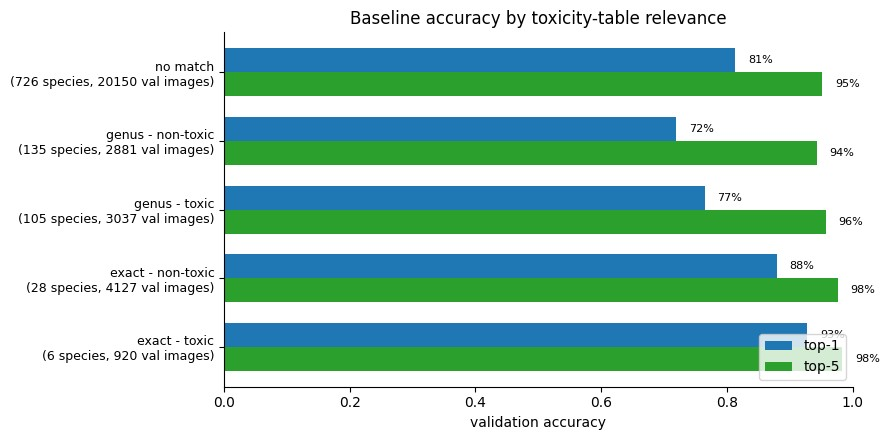

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cats_present = [c for c in CATEGORY_ORDER if c in category_stats]
y = np.arange(len(cats_present))
height = 0.35
ax.barh(y - height / 2, category_df["top-1"], height, label="top-1", color="#1f77b4")
ax.barh(y + height / 2, category_df["top-5"], height, label="top-5", color="#2ca02c")
ax.set_yticks(y)
ax.set_yticklabels([
    f"{c}\n({category_stats[c]['n_species']} species, {category_stats[c]['n_eval']} val images)"
    for c in cats_present
], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("validation accuracy")
ax.set_xlim(0, 1)
ax.set_title("Baseline accuracy by toxicity-table relevance")
ax.legend(loc="lower right")
for i, c in enumerate(cats_present):
    ax.text(category_df["top-1"][c] + 0.02, i - height / 2, f"{category_df['top-1'][c]:.0%}", va="center", fontsize=8)
    ax.text(category_df["top-5"][c] + 0.02, i + height / 2, f"{category_df['top-5'][c]:.0%}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Reading this table carefully**: accuracy here tracks training-data
volume (the "mean train images/species" column), not table-relevance
itself - `exact - toxic` only looks strong because it happens to include
`Hypericum perforatum` (6,140 images) averaged in with `Zamia pumila`
(17). This is exactly why section 2's bucket-by-data-volume view is the
more honest baseline to compare a future toxicity-aware run against,
rather than this category view alone - but this table is what we'll
re-run after Phase 2/3 training to see whether a cost-sensitive loss
actually moves these specific numbers, species-category by
species-category.

## Take-aways

- **The dataset is severely long-tailed**: median 21 training images per
  species, mean 244 - a small number of common species dominate.
- **The baseline's 81.2% top-1 / 95.6% top-5 hides a huge split**: species
  with 200+ training images score 86% top-1, species with under 20 score
  13% - barely better than chance for most of them.
- **Qualitatively, this plays out exactly as the numbers suggest**: the
  common species (`Hypericum perforatum`, 6,140 images) is identified at
  98.8% confidence; the rarest of the six toxicity-relevant species
  (`Zamia pumila`, 17 images) is never picked first, but at least stays
  in the top-5 - confused for a close relative in the same genus
  (`Zamia furfuracea`); the under-represented `Aralia spinosa` (46
  images) misses the top-5 entirely, unconfident (16%) and wrong about
  everything.
- **Toxicity-table relevance itself doesn't predict accuracy - data
  volume does**
  (section 4): the categories with the strongest numbers just happen to
  contain better-represented species, not because the model treats
  cat-toxic species specially in any way (it has no way to - species ID
  and toxicity are fully separate stages, by design).
- **This is the concrete case for Phase 2/3** (class-balanced sampling /
  cost-sensitive loss): the 20-199 image bucket in particular is a
  realistic target - there's real signal there currently being
  drowned out, unlike the under-10-image extreme where no reweighting
  trick can manufacture data that doesn't exist. Section 4's table is
  the baseline to re-check against once that training actually happens.